# Dia 25 — Trabalhando com APIs em Python: `requests`, `httpx`, JSON e dados linguísticos

**Fase 1 — Fundamentos de Python** · 24/11/2026 · Gutemberg Rapôso

> Linguística + Data Science + NLP aplicado à educação

### Objetivos de aprendizagem

Ao final deste notebook, eu devo ser capaz de:

1. Explicar o básico de HTTP e REST: métodos (GET, POST), códigos de status e cabeçalhos.
2. Usar `requests` para fazer chamadas GET, ler o objeto `Response`, interpretar JSON e tratar erros.
3. Consultar APIs públicas reais **sem chave**: **Open Library**, **Wikipedia REST/Action API** e **Datamuse**.
4. Usar `httpx` de forma síncrona e **assíncrona** e comparar com `requests`.
5. Reaproveitar conexões com `Session`/`Client` (connection pooling).
6. Implementar *rate limiting* (pausa fixa e *token bucket*), *retry* com *backoff* exponencial (manual e `tenacity`).
7. Lidar com paginação (offset/limit e cursor/`continue`).
8. Fazer cache de respostas (`functools.lru_cache`, cache manual em dicionário e `requests_cache`).
9. Converter respostas JSON em `pandas.DataFrame` e montar um **mini-corpus** da Wikipedia sobre métodos de ensino de línguas.

**Observação honesta:** todas as chamadas usam endpoints públicos reais, mas a rede pode falhar. Cada célula tem `try/except` e `timeout`, então o notebook roda mesmo offline — nesse caso, os resultados ficam vazios e isso é indicado na saída. Contagens e frequências dependem do conteúdo das APIs no momento da execução.

In [1]:
# Core imports used throughout the notebook
from __future__ import annotations

import asyncio
import functools
import json
import logging
import os
import re
import tempfile
import time
from collections import Counter
from pathlib import Path
from typing import Any, Callable, Iterator

import httpx
import matplotlib.pyplot as plt
import pandas as pd
import requests

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)

print(f"requests {requests.__version__} | httpx {httpx.__version__} | pandas {pd.__version__}")

requests 2.34.2 | httpx 0.28.1 | pandas 2.3.3


In [2]:
# Shared configuration: a descriptive User-Agent is required by Wikipedia's API etiquette
USER_AGENT = "GutembergPortfolio/1.0 (DS learning notebook; gtmbrgfox@gmail.com)"
HEADERS = {"User-Agent": USER_AGENT, "Accept": "application/json"}
TIMEOUT = 15  # seconds — ALWAYS pass a timeout; requests has no default timeout

OPEN_LIBRARY = "https://openlibrary.org"
WIKI_REST = "https://en.wikipedia.org/api/rest_v1"
WIKI_ACTION = "https://en.wikipedia.org/w/api.php"
DATAMUSE = "https://api.datamuse.com"

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(name)s | %(message)s", force=True)
log = logging.getLogger("api")


def network_available(url: str = "https://api.datamuse.com/words?ml=test&max=1") -> bool:
    """Return True if a lightweight request to a public API succeeds."""
    try:
        return requests.get(url, headers=HEADERS, timeout=5).ok
    except requests.RequestException:
        return False


ONLINE = network_available()
print("Network available:", ONLINE)

Network available: True


## 1. HTTP e REST em poucas palavras

Uma **API REST** expõe *recursos* (livros, artigos, palavras) por meio de **URLs**, e nós interagimos com eles via **métodos HTTP**:

| Método | Uso típico | Idempotente? |
| --- | --- | --- |
| `GET` | ler um recurso | sim |
| `POST` | criar/enviar dados | não |
| `PUT` / `PATCH` | substituir / atualizar parcialmente | `PUT` sim, `PATCH` depende |
| `DELETE` | remover | sim |

**Códigos de status** (a "pragmática" da resposta):

- `2xx` sucesso (`200 OK`, `201 Created`)
- `3xx` redirecionamento (`301`, `304 Not Modified`)
- `4xx` erro do cliente (`400 Bad Request`, `401 Unauthorized`, `404 Not Found`, `429 Too Many Requests`)
- `5xx` erro do servidor (`500`, `502`, `503 Service Unavailable`)

**Cabeçalhos (headers)** são metadados: `User-Agent` (quem pede), `Accept` (formato desejado), `Content-Type` (formato enviado), `Authorization` (credenciais), `Retry-After` (quando tentar de novo).

Analogia linguística: a URL é o *enunciado*, o método é o *ato de fala* (perguntar vs. ordenar), os headers são o *contexto* e o status é a *resposta pragmática* do interlocutor.

In [3]:
# Anatomy of a request — built and inspected WITHOUT sending it
req = requests.Request(
    method="GET",
    url=f"{DATAMUSE}/words",
    params={"ml": "language learning", "max": 5},
    headers=HEADERS,
).prepare()

print("Method :", req.method)
print("URL    :", req.url)  # params are URL-encoded automatically
print("Headers:", dict(req.headers))

# A POST carries a body; json= sets Content-Type: application/json
post = requests.Request("POST", "https://httpbin.org/post", json={"word": "fluency", "cefr": "B2"}).prepare()
print("\nPOST body   :", post.body)
print("Content-Type:", post.headers["Content-Type"])

Method : GET
URL    : https://api.datamuse.com/words?ml=language+learning&max=5
Headers: {'User-Agent': 'GutembergPortfolio/1.0 (DS learning notebook; gtmbrgfox@gmail.com)', 'Accept': 'application/json'}

POST body   : b'{"word": "fluency", "cefr": "B2"}'
Content-Type: application/json


In [4]:
# Status-code families as a small lookup helper
from http import HTTPStatus


def describe_status(code: int) -> str:
    """Return a human-readable description of an HTTP status code."""
    family = {1: "informational", 2: "success", 3: "redirection", 4: "client error", 5: "server error"}[code // 100]
    try:
        phrase = HTTPStatus(code).phrase
    except ValueError:
        phrase = "unknown"
    return f"{code} {phrase} ({family})"


for code in (200, 201, 304, 400, 401, 404, 429, 500, 503):
    print(describe_status(code))

200 OK (success)
201 Created (success)
304 Not Modified (redirection)
400 Bad Request (client error)
401 Unauthorized (client error)
404 Not Found (client error)
429 Too Many Requests (client error)
500 Internal Server Error (server error)
503 Service Unavailable (server error)


## 2. A biblioteca `requests`: GET, objeto `Response`, JSON e erros

`requests` é a biblioteca HTTP mais popular em Python. Pontos essenciais:

- `requests.get(url, params=..., headers=..., timeout=...)` → `Response`.
- `response.status_code`, `response.headers`, `response.text`, `response.json()`, `response.elapsed`, `response.url`.
- `response.raise_for_status()` transforma `4xx/5xx` em exceção (`HTTPError`).
- **Sempre** use `timeout`: sem ele, uma chamada pode travar para sempre.
- Hierarquia de exceções: `RequestException` → `ConnectionError`, `Timeout`, `HTTPError`, `JSONDecodeError`...

In [5]:
# Basic GET against the Datamuse API ("means like" = semantic neighbours)
try:
    resp = requests.get(f"{DATAMUSE}/words", params={"ml": "pronunciation", "max": 8}, headers=HEADERS, timeout=TIMEOUT)
    print("Status       :", resp.status_code, resp.reason)
    print("Final URL    :", resp.url)
    print("Content-Type :", resp.headers.get("Content-Type"))
    print("Elapsed      :", resp.elapsed.total_seconds(), "s")
    print("Encoding     :", resp.encoding)
    data = resp.json()  # parsed into Python lists/dicts
    print("Type of data :", type(data).__name__, "| first item:", data[0] if data else None)
except requests.RequestException as exc:
    print("Request failed (offline?):", exc)
    data = []

Status       : 200 OK
Final URL    : https://api.datamuse.com/words?ml=pronunciation&max=8
Content-Type : application/json
Elapsed      : 0.053036 s
Encoding     : utf-8
Type of data : list | first item: {'word': 'voice', 'score': 29947605, 'tags': ['n', 'results_type:primary_rel']}


In [6]:
# Parsing JSON: json.loads on text == response.json(); nested access needs defensive .get()
raw = '{"word": "syntax", "score": 900, "tags": ["n", "f:12.3"], "defs": null}'
parsed = json.loads(raw)
print(parsed["word"], parsed.get("defs", "no defs"), parsed.get("missing_key", "<default>"))

# Frequency tag "f:<per million>" is a Datamuse convention when md=f is requested
freq = next((float(t[2:]) for t in parsed["tags"] if t.startswith("f:")), None)
print("Frequency per million:", freq)

# Round-trip back to a pretty JSON string (ensure_ascii=False keeps Portuguese accents)
print(json.dumps({"palavra": "pronúncia", "nível": "B1"}, ensure_ascii=False, indent=2))

syntax None <default>
Frequency per million: 12.3
{
  "palavra": "pronúncia",
  "nível": "B1"
}


In [7]:
def safe_get_json(url: str, params: dict | None = None, timeout: float = TIMEOUT) -> Any | None:
    """GET a URL and return parsed JSON, or None on any network/HTTP/JSON error.

    Each failure type is logged separately so the cause is visible.
    """
    try:
        r = requests.get(url, params=params, headers=HEADERS, timeout=timeout)
        r.raise_for_status()
        return r.json()
    except requests.Timeout:
        log.warning("Timeout after %ss: %s", timeout, url)
    except requests.ConnectionError as exc:
        log.warning("Connection error: %s", exc.__class__.__name__)
    except requests.HTTPError as exc:
        log.warning("HTTP error %s for %s", exc.response.status_code, url)
    except requests.JSONDecodeError:
        log.warning("Response was not valid JSON: %s", url)
    return None


# 1) a resource that does not exist -> 404 HTTPError (Wikipedia REST)
safe_get_json(f"{WIKI_REST}/page/summary/This_Page_Should_Not_Exist_12345xyz")
# 2) an absurdly small timeout -> Timeout
safe_get_json(f"{DATAMUSE}/words", params={"ml": "grammar"}, timeout=0.0001)
# 3) a domain that does not resolve -> ConnectionError
safe_get_json("https://no-such-host.invalid/api")
# 4) a valid call
print(safe_get_json(f"{DATAMUSE}/words", params={"sl": "through", "max": 3}))

2026-11-24 00:38:37,509 | WARNING | api | HTTP error 404 for https://en.wikipedia.org/api/rest_v1/page/summary/This_Page_Should_Not_Exist_12345xyz


2026-11-24 00:38:37,518 | WARNING | api | Timeout after 0.0001s: https://api.datamuse.com/words


2026-11-24 00:38:37,522 | WARNING | api | Connection error: ConnectionError


[{'word': 'through', 'score': 100, 'numSyllables': 1}, {'word': 'threw', 'score': 100, 'numSyllables': 1}, {'word': 'theroux', 'score': 100, 'numSyllables': 2}]


## 3. Exemplo real: Open Library API — livros de linguística e aprendizagem de línguas

A [Open Library Search API](https://openlibrary.org/dev/docs/api/search) aceita `q`, `subject`, `limit`, `offset`/`page` e `fields` (para pedir só as colunas necessárias — economiza banda e é uma boa prática).

In [8]:
def search_books_by_subject(subject: str, limit: int = 20, offset: int = 0) -> dict:
    """Search Open Library by subject and return the raw JSON payload (or an empty payload)."""
    params = {
        "subject": subject,
        "limit": limit,
        "offset": offset,
        "fields": "key,title,author_name,first_publish_year,edition_count,language,subject",
    }
    payload = safe_get_json(f"{OPEN_LIBRARY}/search.json", params=params, timeout=30)
    return payload or {"numFound": 0, "docs": []}


ling = search_books_by_subject("linguistics", limit=20)
print("Books found for 'linguistics':", ling.get("numFound"))
for doc in ling["docs"][:5]:
    print(f"- {doc.get('title')!r} | {', '.join(doc.get('author_name', ['?'])[:2])} | {doc.get('first_publish_year')}")

Books found for 'linguistics': 47071
- 'Metode dan aneka teknik analisis bahasa' | Sudaryanto. | 1993
- 'A concise introduction to linguistics' | Bruce M. Rowe | 2005
- 'Introducing applied linguistics' | S.P. Corder | 1973
- 'Introducing discourse analysis' | David Nunan | 1993
- 'Roots' | Alex Haley | 1861


In [9]:
# Flatten the nested JSON into a DataFrame: lists -> first item / count
def books_to_frame(docs: list[dict], subject: str) -> pd.DataFrame:
    """Convert Open Library search docs into a tidy DataFrame."""
    rows = [
        {
            "subject_query": subject,
            "title": d.get("title"),
            "first_author": (d.get("author_name") or [None])[0],
            "first_publish_year": d.get("first_publish_year"),
            "edition_count": d.get("edition_count", 0),
            "n_languages": len(d.get("language", [])),
            "n_subjects": len(d.get("subject", [])),
            "key": d.get("key"),
        }
        for d in docs
    ]
    return pd.DataFrame(rows)


subjects = ["linguistics", "language acquisition", "english language study and teaching"]
frames = []
for subj in subjects:
    frames.append(books_to_frame(search_books_by_subject(subj, limit=25)["docs"], subj))
    time.sleep(0.5)  # be polite between calls
books = pd.concat(frames, ignore_index=True)
print(books.shape)
books.head(8)

(75, 8)


,subject_query,title,first_author,first_publish_year,edition_count,n_languages,n_subjects,key
0,linguistics,Metode dan aneka teknik analisis bahasa,Sudaryanto.,1993,2,1,3,/works/OL3729346W
1,linguistics,A concise introduction to linguistics,Bruce M. Rowe,2005,25,1,1,/works/OL2197866W
2,linguistics,Introducing applied linguistics,S.P. Corder,1973,4,1,3,/works/OL5496387W
3,linguistics,Introducing discourse analysis,David Nunan,1993,1,1,4,/works/OL3529439W
4,linguistics,Roots,Alex Haley,1861,65,7,42,/works/OL1815447W
5,linguistics,Pygmalion,George Bernard Shaw,1912,143,8,17,/works/OL1066524W
6,linguistics,The study of language,George Yule,1985,30,2,8,/works/OL1390239W
7,linguistics,Linguistics,David Crystal,1971,6,1,3,/works/OL114346W


In [10]:
# Quick analysis: editions and publication years per subject query
if not books.empty:
    summary = (
        books.groupby("subject_query")
        .agg(n_books=("title", "size"), median_year=("first_publish_year", "median"),
             total_editions=("edition_count", "sum"), max_languages=("n_languages", "max"))
        .sort_values("total_editions", ascending=False)
    )
    display(summary)
    print("Most-edited titles:")
    display(books.nlargest(5, "edition_count")[["subject_query", "title", "first_author", "edition_count"]])
    print("Subject tags are crowd-sourced: classic literature used in ESL courses (and some odd years) show up — inspect before trusting.")
else:
    print("No data (offline).")

,n_books,median_year,total_editions,max_languages
subject_query,,,,
english language study and teaching,25,1983.0,2853,20
linguistics,25,1987.0,470,8
language acquisition,25,1997.0,190,6


Most-edited titles:


,subject_query,title,first_author,edition_count
58,english language study and teaching,Through the Looking-Glass,Lewis Carroll,1379
69,english language study and teaching,The Happy Prince and other tales,Oscar Wilde,508
54,english language study and teaching,The Elements of Style,"William Strunk, Jr.",288
65,english language study and teaching,Murder on the Links,Agatha Christie,273
5,linguistics,Pygmalion,George Bernard Shaw,143


Subject tags are crowd-sourced: classic literature used in ESL courses (and some odd years) show up — inspect before trusting.


## 4. `httpx`: API parecida com `requests`, mas com suporte a async e HTTP/2

`httpx` mantém uma interface quase idêntica à de `requests` (`httpx.get`, `.json()`, `.raise_for_status()`), com diferenças importantes:

| Aspecto | `requests` | `httpx` |
| --- | --- | --- |
| Síncrono | ✅ | ✅ |
| Assíncrono (`async/await`) | ❌ | ✅ `AsyncClient` |
| Timeout padrão | **nenhum** | 5 s |
| Redirecionamentos | segue por padrão | **não** segue por padrão (`follow_redirects=True`) |
| HTTP/2 | ❌ | ✅ (opcional, `httpx[http2]`) |
| Transporte mock para testes | via libs externas | ✅ `MockTransport` nativo |

Em Jupyter, o *event loop* já está rodando, então usamos `await` diretamente na célula (em um script, seria `asyncio.run(main())`).

In [11]:
# Synchronous httpx — same mental model as requests
try:
    r = httpx.get(f"{DATAMUSE}/words", params={"rel_rhy": "speech", "max": 10}, headers=HEADERS, timeout=TIMEOUT)
    r.raise_for_status()
    print(r.status_code, r.http_version, "| rhymes with 'speech':", [w["word"] for w in r.json()])
except httpx.HTTPError as exc:  # base class for transport + status errors in httpx
    print("httpx request failed:", exc.__class__.__name__, exc)

2026-11-24 00:38:41,100 | INFO | httpx | HTTP Request: GET https://api.datamuse.com/words?rel_rhy=speech&max=10 "HTTP/1.1 200 OK"


200 HTTP/1.1 | rhymes with 'speech': ['breach', 'reach', 'peach', 'beseech', 'dreich', 'screech', 'outreach', 'preach', 'leach', 'bleach']


In [12]:
# Asynchronous httpx: fetch several Wikipedia summaries concurrently
TERMS = ["Phonology", "Morphology_(linguistics)", "Syntax", "Semantics", "Pragmatics", "Sociolinguistics"]


async def fetch_summary_async(client: httpx.AsyncClient, title: str) -> dict:
    """Fetch one Wikipedia REST summary; never raises, returns an error record instead."""
    try:
        r = await client.get(f"{WIKI_REST}/page/summary/{title}")
        r.raise_for_status()
        j = r.json()
        return {"title": j.get("title"), "chars": len(j.get("extract", "")), "ok": True}
    except httpx.HTTPError as exc:
        return {"title": title, "chars": 0, "ok": False, "error": exc.__class__.__name__}


async def fetch_all_async(titles: list[str]) -> list[dict]:
    """Run all summary requests concurrently with a shared connection pool."""
    limits = httpx.Limits(max_connections=4)  # cap concurrency to stay polite
    async with httpx.AsyncClient(headers=HEADERS, timeout=TIMEOUT, follow_redirects=True, limits=limits) as client:
        return await asyncio.gather(*(fetch_summary_async(client, t) for t in titles))


t0 = time.perf_counter()
async_results = await fetch_all_async(TERMS)
t_async = time.perf_counter() - t0
pd.DataFrame(async_results)

2026-11-24 00:38:41,228 | INFO | httpx | HTTP Request: GET https://en.wikipedia.org/api/rest_v1/page/summary/Morphology_(linguistics) "HTTP/1.1 200 OK"


2026-11-24 00:38:41,241 | INFO | httpx | HTTP Request: GET https://en.wikipedia.org/api/rest_v1/page/summary/Syntax "HTTP/1.1 200 OK"


2026-11-24 00:38:41,243 | INFO | httpx | HTTP Request: GET https://en.wikipedia.org/api/rest_v1/page/summary/Phonology "HTTP/1.1 200 OK"


2026-11-24 00:38:41,244 | INFO | httpx | HTTP Request: GET https://en.wikipedia.org/api/rest_v1/page/summary/Semantics "HTTP/1.1 200 OK"


2026-11-24 00:38:41,252 | INFO | httpx | HTTP Request: GET https://en.wikipedia.org/api/rest_v1/page/summary/Pragmatics "HTTP/1.1 200 OK"


2026-11-24 00:38:41,268 | INFO | httpx | HTTP Request: GET https://en.wikipedia.org/api/rest_v1/page/summary/Sociolinguistics "HTTP/1.1 200 OK"


,title,chars,ok
0,Phonology,669,True
1,Morphology (linguistics),937,True
2,Syntax,541,True
3,Semantics,646,True
4,Pragmatics,426,True
5,Sociolinguistics,555,True


In [13]:
# Same work, sequentially with requests — compare wall-clock time (machine/network dependent)
t0 = time.perf_counter()
seq_results = []
for t in TERMS:
    j = safe_get_json(f"{WIKI_REST}/page/summary/{t}")
    seq_results.append({"title": t, "ok": j is not None})
t_seq = time.perf_counter() - t0
print(f"sequential requests: {t_seq:.2f}s | async httpx (max 4 connections): {t_async:.2f}s")
print("Note: a single timing is noisy; it illustrates I/O-bound concurrency, not a benchmark.")

sequential requests: 0.53s | async httpx (max 4 connections): 0.16s
Note: a single timing is noisy; it illustrates I/O-bound concurrency, not a benchmark.


## 5. `Session` / `Client`: reaproveitando conexões (connection pooling)

Cada `requests.get()` avulso abre uma conexão TCP + handshake TLS nova. Uma `requests.Session` (ou `httpx.Client`):

- mantém **conexões abertas** (keep-alive) e as reutiliza → menos latência;
- guarda **headers, cookies e autenticação** compartilhados;
- permite montar um `HTTPAdapter` com tamanho de pool e política de *retry*.

Regra prática: **várias chamadas ao mesmo host → use uma sessão**, de preferência com `with` para fechar as conexões no fim.

In [14]:
words = ["fluency", "accuracy", "grammar", "vocabulary", "accent", "dialect", "register", "idiom"]


def time_calls(getter: Callable[[str], Any]) -> float:
    """Time a series of Datamuse calls using the supplied getter function."""
    t0 = time.perf_counter()
    for w in words:
        try:
            getter(w)
        except requests.RequestException:
            pass
    return time.perf_counter() - t0


no_session = time_calls(lambda w: requests.get(f"{DATAMUSE}/words", params={"ml": w, "max": 3}, headers=HEADERS, timeout=TIMEOUT))

with requests.Session() as session:
    session.headers.update(HEADERS)  # set once, sent on every request
    with_session = time_calls(lambda w: session.get(f"{DATAMUSE}/words", params={"ml": w, "max": 3}, timeout=TIMEOUT))

print(f"{len(words)} calls without session: {no_session:.2f}s | with session: {with_session:.2f}s")

8 calls without session: 0.34s | with session: 0.11s


In [15]:
# A production-style session factory: pooled adapter + urllib3 Retry for transient errors
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry


def build_session(total_retries: int = 3, backoff: float = 0.5, pool: int = 10) -> requests.Session:
    """Create a Session with connection pooling and automatic retries on 429/5xx."""
    retry = Retry(
        total=total_retries,
        backoff_factor=backoff,                 # sleeps 0.5, 1, 2 ... seconds
        status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods=("GET", "HEAD"),        # only retry idempotent methods
        respect_retry_after_header=True,
    )
    adapter = HTTPAdapter(max_retries=retry, pool_connections=pool, pool_maxsize=pool)
    s = requests.Session()
    s.mount("https://", adapter)
    s.mount("http://", adapter)
    s.headers.update(HEADERS)
    return s


api = build_session()
print(api.adapters["https://"].max_retries)

Retry(total=3, connect=None, read=None, redirect=None, status=None)


## 6. *Rate limiting*: respeitando os limites da API

APIs públicas limitam quantas requisições aceitam por intervalo (a Datamuse pede até ~100.000/dia; a Wikipedia pede uso "razoável" e um `User-Agent` identificável). Estratégias:

1. **Pausa fixa** (`time.sleep(x)`) entre chamadas — simples, mas desperdiça tempo.
2. **Intervalo mínimo** — só dorme o necessário desde a última chamada.
3. **Token bucket** — um "balde" com capacidade `C` que se reabastece a `r` tokens/s; cada requisição consome 1 token. Permite **rajadas** curtas sem ultrapassar a taxa média.

Se o servidor responder `429`, leia o header `Retry-After`.

In [16]:
class TokenBucket:
    """Thread-unsafe token bucket rate limiter (sufficient for sequential notebooks).

    Args:
        rate: tokens added per second (average allowed request rate).
        capacity: maximum burst size.
    """

    def __init__(self, rate: float, capacity: int) -> None:
        self.rate = rate
        self.capacity = capacity
        self.tokens = float(capacity)
        self.last = time.monotonic()

    def _refill(self) -> None:
        now = time.monotonic()
        self.tokens = min(self.capacity, self.tokens + (now - self.last) * self.rate)
        self.last = now

    def acquire(self) -> float:
        """Block until a token is available; return the seconds waited."""
        self._refill()
        waited = 0.0
        if self.tokens < 1:
            waited = (1 - self.tokens) / self.rate
            time.sleep(waited)
            self._refill()
        self.tokens -= 1
        return waited


# Simulation (no network): 10 "requests" with burst 3 and 5 req/s average
bucket = TokenBucket(rate=5, capacity=3)
t0 = time.perf_counter()
waits = [round(bucket.acquire(), 3) for _ in range(10)]
print("waits per request:", waits)
print(f"10 acquisitions took {time.perf_counter() - t0:.2f}s (first 3 are an immediate burst)")

waits per request: [0.0, 0.0, 0.0, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2]
10 acquisitions took 1.40s (first 3 are an immediate burst)


In [17]:
def rate_limited(calls_per_second: float) -> Callable:
    """Decorator enforcing a minimum interval between calls of the wrapped function."""
    min_interval = 1.0 / calls_per_second

    def decorator(func: Callable) -> Callable:
        last_call = [0.0]

        @functools.wraps(func)
        def wrapper(*args, **kwargs):
            elapsed = time.monotonic() - last_call[0]
            if elapsed < min_interval:
                time.sleep(min_interval - elapsed)
            last_call[0] = time.monotonic()
            return func(*args, **kwargs)

        return wrapper

    return decorator


@rate_limited(calls_per_second=4)
def sounds_like(word: str) -> list[str]:
    """Return words that sound like `word` (Datamuse sl=), rate limited to 4 calls/s."""
    data = safe_get_json(f"{DATAMUSE}/words", params={"sl": word, "max": 5}) or []
    return [d["word"] for d in data]


t0 = time.perf_counter()
for w in ["though", "thought", "through", "tough"]:  # classic English spelling-pronunciation trap
    print(f"{w:8s} -> {sounds_like(w)}")
print(f"elapsed {time.perf_counter() - t0:.2f}s (>= 0.75s guaranteed by the limiter)")

though   -> ['though', 'tho', 'thoe', 'tha', 'thaa']


thought  -> ['thought', 'thaught', 'thot', 'that', 'thawed']


through  -> ['through', 'threw', 'thru', 'theroux', 'thoreau']


tough    -> ['tough', 'tuff', 'tuf', 'tef', 'tefe']
elapsed 0.80s (>= 0.75s guaranteed by the limiter)


## 7. *Retry* com *backoff* exponencial (manual e `tenacity`)

Erros **transitórios** (timeouts, `429`, `502/503`) costumam desaparecer se tentarmos de novo — mas não imediatamente. O padrão é **backoff exponencial com jitter**: esperar `base × 2^tentativa + aleatório`, até um limite.

Não faça *retry* de erros **permanentes** (`400`, `401`, `404`): repetir não muda a resposta.

Para testar de forma **determinística**, uso o `httpx.MockTransport`, que simula um servidor que falha duas vezes com `503` antes de responder `200`. Isso não substitui a API real — é uma ferramenta de teste.

In [18]:
import random

RETRYABLE = {429, 500, 502, 503, 504}


def get_with_backoff(client: httpx.Client, url: str, max_attempts: int = 5, base: float = 0.1, cap: float = 2.0) -> httpx.Response:
    """GET with manual exponential backoff + jitter; retries only transient failures."""
    for attempt in range(1, max_attempts + 1):
        try:
            r = client.get(url)
            if r.status_code not in RETRYABLE:
                r.raise_for_status()  # permanent 4xx errors raise immediately
                return r
            reason = f"status {r.status_code}"
        except (httpx.TimeoutException, httpx.TransportError) as exc:
            reason = exc.__class__.__name__
        if attempt == max_attempts:
            raise RuntimeError(f"giving up after {attempt} attempts ({reason})")
        delay = min(cap, base * 2 ** (attempt - 1)) + random.uniform(0, base)
        log.info("attempt %d failed (%s); sleeping %.2fs", attempt, reason, delay)
        time.sleep(delay)


# Deterministic flaky server: 503, 503, then 200
calls = {"n": 0}


def flaky_handler(request: httpx.Request) -> httpx.Response:
    calls["n"] += 1
    if calls["n"] < 3:
        return httpx.Response(503, json={"error": "busy"})
    return httpx.Response(200, json=[{"word": "lexicon", "score": 1000}])


with httpx.Client(transport=httpx.MockTransport(flaky_handler)) as mock_client:
    resp = get_with_backoff(mock_client, "https://mock.local/words")
    print("final:", resp.status_code, resp.json(), "| server calls:", calls["n"])

2026-11-24 00:38:44,494 | INFO | httpx | HTTP Request: GET https://mock.local/words "HTTP/1.1 503 Service Unavailable"


2026-11-24 00:38:44,495 | INFO | api | attempt 1 failed (status 503); sleeping 0.19s


2026-11-24 00:38:44,690 | INFO | httpx | HTTP Request: GET https://mock.local/words "HTTP/1.1 503 Service Unavailable"


2026-11-24 00:38:44,691 | INFO | api | attempt 2 failed (status 503); sleeping 0.20s


2026-11-24 00:38:44,894 | INFO | httpx | HTTP Request: GET https://mock.local/words "HTTP/1.1 200 OK"


final: 200 [{'word': 'lexicon', 'score': 1000}] | server calls: 3


In [19]:
# The same policy declaratively with tenacity
from tenacity import (RetryError, retry, retry_if_exception, stop_after_attempt,
                      wait_exponential_jitter, before_sleep_log)


def is_transient(exc: BaseException) -> bool:
    """Retry on transport errors and retryable HTTP status codes only."""
    if isinstance(exc, httpx.HTTPStatusError):
        return exc.response.status_code in RETRYABLE
    return isinstance(exc, httpx.TransportError)


@retry(
    retry=retry_if_exception(is_transient),
    stop=stop_after_attempt(4),
    wait=wait_exponential_jitter(multiplier=0.1, max=1.0, jitter=0.1),
    before_sleep=before_sleep_log(log, logging.INFO),
    reraise=True,
)
def fetch_json_tenacity(client: httpx.Client, url: str) -> Any:
    """GET + raise_for_status, retried by tenacity on transient errors."""
    r = client.get(url)
    r.raise_for_status()
    return r.json()


calls["n"] = 0
with httpx.Client(transport=httpx.MockTransport(flaky_handler)) as mock_client:
    print("tenacity result:", fetch_json_tenacity(mock_client, "https://mock.local/words"), "| calls:", calls["n"])

# A permanent 404 is NOT retried: exactly one call
not_found_calls = {"n": 0}


def not_found(request):
    not_found_calls["n"] += 1
    return httpx.Response(404)


with httpx.Client(transport=httpx.MockTransport(not_found)) as mock_client:
    try:
        fetch_json_tenacity(mock_client, "https://mock.local/missing")
    except httpx.HTTPStatusError as exc:
        print("404 raised immediately; calls =", not_found_calls["n"])

# And against the real Datamuse API (works on first try when online)
with httpx.Client(headers=HEADERS, timeout=TIMEOUT) as real:
    try:
        print("real call:", [w["word"] for w in fetch_json_tenacity(real, f"{DATAMUSE}/words?rel_syn=teach&max=5")])
    except httpx.HTTPError as exc:
        print("real call failed:", exc.__class__.__name__)

2026-11-24 00:38:44,909 | INFO | httpx | HTTP Request: GET https://mock.local/words "HTTP/1.1 503 Service Unavailable"


2026-11-24 00:38:44,910 | INFO | api | Retrying __main__.fetch_json_tenacity in 0.141 seconds as it raised HTTPStatusError: Server error '503 Service Unavailable' for url 'https://mock.local/words'
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/503.


2026-11-24 00:38:45,052 | INFO | httpx | HTTP Request: GET https://mock.local/words "HTTP/1.1 503 Service Unavailable"


2026-11-24 00:38:45,053 | INFO | api | Retrying __main__.fetch_json_tenacity in 0.282 seconds as it raised HTTPStatusError: Server error '503 Service Unavailable' for url 'https://mock.local/words'
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/503.


2026-11-24 00:38:45,336 | INFO | httpx | HTTP Request: GET https://mock.local/words "HTTP/1.1 200 OK"


2026-11-24 00:38:45,338 | INFO | httpx | HTTP Request: GET https://mock.local/missing "HTTP/1.1 404 Not Found"


2026-11-24 00:38:45,381 | INFO | httpx | HTTP Request: GET https://api.datamuse.com/words?rel_syn=teach&max=5 "HTTP/1.1 200 OK"


tenacity result: [{'word': 'lexicon', 'score': 1000}] | calls: 3
404 raised immediately; calls = 1
real call: ['instruct', 'thatch', 'edward thatch', 'edward teach', 'blackbeard']


## 8. Paginação: offset/limit e cursor

APIs raramente devolvem tudo de uma vez:

- **Offset/limit (ou page)** — `?limit=20&offset=40`. Simples, permite pular páginas, mas pode duplicar/omitir itens se os dados mudarem entre chamadas. A Open Library usa esse modelo.
- **Cursor/token** — a resposta traz um marcador opaco para a próxima página (`continue`, `next_cursor`). Mais estável para dados que mudam. A **MediaWiki Action API** (Wikipedia) usa o objeto `continue`.

Um **gerador** (`yield`) é a forma idiomática de esconder a paginação de quem consome os dados.

In [20]:
def paginate_open_library(subject: str, page_size: int = 50, max_items: int = 150) -> Iterator[dict]:
    """Yield Open Library docs page by page using offset/limit until max_items or exhaustion."""
    offset = 0
    with build_session() as s:
        while offset < max_items:
            params = {"subject": subject, "limit": page_size, "offset": offset,
                      "fields": "title,author_name,first_publish_year"}
            try:
                r = s.get(f"{OPEN_LIBRARY}/search.json", params=params, timeout=30)
                r.raise_for_status()
                docs = r.json().get("docs", [])
            except requests.RequestException as exc:
                log.warning("pagination stopped at offset %d: %s", offset, exc.__class__.__name__)
                return
            if not docs:
                return
            log.info("offset=%d -> %d docs", offset, len(docs))
            yield from docs
            offset += page_size
            time.sleep(0.5)


sla_books = pd.DataFrame(list(paginate_open_library("second language acquisition", page_size=50, max_items=150)))
print("rows:", len(sla_books), "| unique titles:", sla_books["title"].nunique() if not sla_books.empty else 0)
sla_books.head()

2026-11-24 00:38:45,675 | INFO | api | offset=0 -> 50 docs


2026-11-24 00:38:46,367 | INFO | api | offset=50 -> 50 docs


2026-11-24 00:38:47,056 | INFO | api | offset=100 -> 50 docs


rows: 150 | unique titles: 134


,author_name,first_publish_year,title
0,"[Susan M. Gass, Larry Selinker]",1994.0,Second language acquisition
1,[Rod Ellis],1997.0,Second language acquisition
2,[Lourdes Ortega],2008.0,Understanding Second Language Acquisition
3,"[David Singleton, Simone E. Pfenninger]",2015.0,Second Language Acquisition
4,"[Bill VanPatten, Gregory D. Keating, Stefanie Wulff]",2020.0,Theories in Second Language Acquisition


In [21]:
def wiki_category_members(category: str, batch: int = 50, max_items: int = 200) -> Iterator[dict]:
    """Yield pages in a Wikipedia category using cursor-based ('continue') pagination."""
    params = {"action": "query", "list": "categorymembers", "cmtitle": f"Category:{category}",
              "cmlimit": batch, "cmtype": "page", "format": "json", "formatversion": 2}
    fetched = 0
    with build_session() as s:
        while fetched < max_items:
            try:
                r = s.get(WIKI_ACTION, params=params, timeout=TIMEOUT)
                r.raise_for_status()
                payload = r.json()
            except requests.RequestException as exc:
                log.warning("category pagination failed: %s", exc.__class__.__name__)
                return
            members = payload.get("query", {}).get("categorymembers", [])
            fetched += len(members)
            yield from members
            if "continue" not in payload:   # no cursor => last page
                return
            params.update(payload["continue"])  # e.g. {'cmcontinue': 'page|...', 'continue': '-||'}
            time.sleep(0.2)


methods_pages = pd.DataFrame(list(wiki_category_members("Second-language_acquisition", batch=20, max_items=100)))
print("pages in category:", len(methods_pages))
methods_pages.head(10)

pages in category: 58


,pageid,ns,title
0,1199964,0,Second-language acquisition
1,39813996,0,Outline of second-language acquisition
2,39049990,0,Acculturation model
3,3158077,0,Assimil
4,3228584,0,Foreign-language assistant
5,43299422,0,Bilingual method
6,33579530,0,CANAL-F
7,77432358,0,Alphonse Chérel
8,7596654,0,Chinese as a foreign language
9,47695603,0,List of common misconceptions about language learning


## 9. Wikipedia REST API: resumos de termos linguísticos

O endpoint `GET /api/rest_v1/page/summary/{title}` devolve título, descrição curta, `extract` (primeiro parágrafo em texto puro) e metadados. É ideal para montar um **glossário** de termos técnicos para alunos.

In [22]:
GLOSSARY_TERMS = ["Phoneme", "Morpheme", "Lexicon", "Code-switching", "Interlanguage",
                  "Language_transfer", "Register_(sociolinguistics)", "Corpus_linguistics"]


def wiki_summary(title: str, session: requests.Session) -> dict:
    """Fetch a Wikipedia summary and keep only the fields useful for a glossary."""
    try:
        r = session.get(f"{WIKI_REST}/page/summary/{title}", timeout=TIMEOUT)
        r.raise_for_status()
        j = r.json()
    except requests.RequestException as exc:
        return {"term": title, "description": None, "extract": None, "error": exc.__class__.__name__}
    return {
        "term": j.get("title"),
        "description": j.get("description"),
        "extract": j.get("extract"),
        "last_edited": j.get("timestamp"),
        "url": j.get("content_urls", {}).get("desktop", {}).get("page"),
    }


with build_session() as s:
    glossary = pd.DataFrame([wiki_summary(t, s) for t in GLOSSARY_TERMS])

glossary["n_words"] = glossary["extract"].fillna("").str.split().str.len()
glossary[["term", "description", "n_words"]]

,term,description,n_words
0,Phoneme,Basic unit of phonology,42
1,Morpheme,Smallest meaningful unit in a language,53
2,Lexicon,Vocabulary of a language or branch of knowledge,38
3,Code-switching,Changing between languages during a conversation,50
4,Interlanguage,Idiolect used by a second language learner,91
5,Language transfer,Influence one language has on the acquisition or intelligibility of another,125
6,Register (sociolinguistics),Form of language used for a particular purpose or in a particular communicat...,92
7,Corpus linguistics,Branch of linguistics that studies language through examples contained in re...,44


In [23]:
# A learner-facing glossary card: first sentence only (naive sentence split on '. ')
def first_sentence(text: str | None) -> str:
    """Return the first sentence of a text, or a placeholder when empty."""
    if not text:
        return "(unavailable)"
    return re.split(r"(?<=[.!?])\s+", text.strip(), maxsplit=1)[0]


for _, row in glossary.head(4).iterrows():
    print(f"■ {row['term']}: {first_sentence(row['extract'])}\n")

■ Phoneme: A phoneme is any set of speech sounds that speakers of a language perceptually regard as a single basic sound that serves to distinguish one word from another.

■ Morpheme: In linguistics, a morpheme is the smallest meaningful constituent of a linguistic expression, especially within a word.

■ Lexicon: A lexicon is the vocabulary of a language or branch of knowledge.

■ Code-switching: In linguistics, code-switching or language alternation is the process of shifting from one linguistic code to another, depending on the social context or conversational setting.



## 10. Datamuse API: relações entre palavras (aplicação de NLP)

A [Datamuse API](https://www.datamuse.com/api/) é um "motor de busca de palavras" gratuito e sem chave. Parâmetros úteis para ensino de inglês:

| Parâmetro | Significado | Uso pedagógico |
| --- | --- | --- |
| `ml=` | *means like* (semântica) | sinônimos aproximados, campos lexicais |
| `rel_syn=` / `rel_ant=` | sinônimos / antônimos | exercícios de vocabulário |
| `rel_rhy=` | rimas perfeitas | poesia, músicas, pronúncia |
| `sl=` | *sounds like* | pares mínimos, confusões de pronúncia |
| `rel_jjb=` | adjetivos que modificam o substantivo | **colocações** (*heavy rain*) |
| `rel_trg=` | palavras "gatilho" associadas | mapas mentais |
| `md=f` | inclui frequência por milhão | nivelamento de vocabulário |

In [24]:
def datamuse(params: dict, session: requests.Session) -> list[dict]:
    """Query Datamuse and return the list of results (empty on error)."""
    try:
        r = session.get(f"{DATAMUSE}/words", params=params, timeout=TIMEOUT)
        r.raise_for_status()
        return r.json()
    except requests.RequestException as exc:
        log.warning("Datamuse failed for %s: %s", params, exc.__class__.__name__)
        return []


TARGET = "learn"
relations = {"ml": "means like", "rel_syn": "synonyms", "rel_trg": "triggers", "rel_rhy": "rhymes"}
with build_session() as s:
    table = {label: [d["word"] for d in datamuse({key: TARGET, "max": 8}, s)] for key, label in relations.items()}
    table["adjectives for 'rain'"] = [d["word"] for d in datamuse({"rel_jjb": "rain", "max": 8}, s)]
    table["antonyms of 'formal'"] = [d["word"] for d in datamuse({"rel_ant": "formal", "max": 8}, s)]
    table["words following 'make'"] = [d["word"] for d in datamuse({"rel_bga": "make", "max": 8}, s)]

pd.DataFrame({k: pd.Series(v, dtype="object") for k, v in table.items()})

,means like,synonyms,triggers,rhymes,adjectives for 'rain',antonyms of 'formal',words following 'make'
0,instruct,ascertain,mistakes,discern,heavy,informal,a
1,teach,see,lesson,taciturn,acid,genus doliolum,the
2,con,check,skills,stern,cold,NaN,it
3,see,determine,lessons,concern,little,NaN,sure
4,read,take,how,spurn,much,NaN,up
5,ascertain,study,learning,return,more,NaN,them
6,study,watch,teach,dern,light,NaN,an
7,find out,read,classroom,churn,torrential,NaN,him


In [25]:
# Frequency-annotated semantic neighbours -> rough "common vs rare" split for vocabulary planning
with build_session() as s:
    neighbours = datamuse({"ml": "speak", "md": "f", "max": 30}, s)

def tag_value(tags: list[str], prefix: str) -> float | None:
    """Extract a numeric Datamuse tag such as 'f:12.5'."""
    return next((float(t.split(":", 1)[1]) for t in tags if t.startswith(prefix)), None)

nb_df = pd.DataFrame(
    [{"word": d["word"], "score": d.get("score"), "freq_per_million": tag_value(d.get("tags", []), "f:")} for d in neighbours]
)
if not nb_df.empty:
    nb_df["band"] = pd.cut(nb_df["freq_per_million"], bins=[0, 1, 10, float("inf")], labels=["rare", "medium", "common"])
    display(nb_df.sort_values("freq_per_million", ascending=False).head(12))
    print(nb_df["band"].value_counts().to_dict())
    print("Bands are arbitrary frequency thresholds, not CEFR levels.")

,word,score,freq_per_million,band
7,say,30040679,252.727692,common
16,tell,30036408,139.059245,common
29,reason,30029912,133.184169,common
28,mean,30031572,130.758789,common
1,talk,40036738,83.738513,common
19,hear,30035924,69.444225,common
17,speech,30036200,65.763867,common
2,address,40022696,56.261427,common
25,explain,30033980,56.082046,common
4,mouth,39804575,49.593571,common


{'common': 20, 'medium': 8, 'rare': 2}
Bands are arbitrary frequency thresholds, not CEFR levels.


In [26]:
# Pronunciation confusions for Brazilian learners: "sounds like" neighbours of classic minimal pairs
pairs = ["ship", "sheep", "think", "sink", "live", "leave"]
with build_session() as s:
    rows = []
    for w in pairs:
        similar = [d["word"] for d in datamuse({"sl": w, "max": 6}, s) if d["word"] != w]
        rows.append({"word": w, "sounds_like": ", ".join(similar[:5])})
        time.sleep(0.1)
pd.DataFrame(rows)

,word,sounds_like
0,ship,"shipp, -ship, schip, schupp, schep"
1,sheep,"schaap, -ship, schip, schappe, schep"
2,think,"thank, thunk, thilk, outthink, athink"
3,sink,"sinc, cinque, cinq, cink, cinc"
4,live,"liw, leave, lave, lav, leiv"
5,leave,"leve, lieve, leiv, lave, lav"


## 11. Cache de respostas

Se a mesma pergunta é feita várias vezes, não faz sentido repetir a chamada — é mais lento e gasta a cota da API. Três níveis:

1. **`functools.lru_cache`** — memoização em memória; os argumentos precisam ser *hashable*; some ao reiniciar o kernel.
2. **Cache manual em dicionário (+ JSON em disco)** — controle total, inclusive de **TTL** (tempo de validade).
3. **`requests_cache`** — cache transparente de uma `Session` em SQLite, respeitando expiração e headers HTTP.

Atenção: dados em cache podem ficar **desatualizados**; escolha um TTL coerente com a frequência de mudança da fonte.

In [27]:
@functools.lru_cache(maxsize=256)
def cached_rhymes(word: str) -> tuple[str, ...]:
    """Return rhymes for a word; tuples are immutable, so the cached value is safe to share."""
    data = safe_get_json(f"{DATAMUSE}/words", params={"rel_rhy": word, "max": 10}) or []
    return tuple(d["word"] for d in data)


for attempt in (1, 2):
    t0 = time.perf_counter()
    result = cached_rhymes("grammar")
    print(f"call {attempt}: {time.perf_counter() - t0:.4f}s -> {result[:5]}")
print(cached_rhymes.cache_info())

call 1: 0.0442s -> ('clamor', 'glamour', 'stammer', 'enamor', 'hammer')
call 2: 0.0000s -> ('clamor', 'glamour', 'stammer', 'enamor', 'hammer')
CacheInfo(hits=1, misses=1, maxsize=256, currsize=1)


In [28]:
class TTLCache:
    """Minimal dict-based cache with time-to-live and optional JSON persistence."""

    def __init__(self, ttl_seconds: float, path: Path | None = None) -> None:
        self.ttl = ttl_seconds
        self.path = path
        self.store: dict[str, tuple[float, Any]] = {}
        if path and path.exists():
            self.store = {k: tuple(v) for k, v in json.loads(path.read_text()).items()}
        self.hits = self.misses = 0

    @staticmethod
    def make_key(url: str, params: dict | None) -> str:
        return url + "?" + json.dumps(params or {}, sort_keys=True)

    def get_json(self, url: str, params: dict | None = None) -> Any:
        key = self.make_key(url, params)
        entry = self.store.get(key)
        if entry and time.time() - entry[0] < self.ttl:
            self.hits += 1
            return entry[1]
        self.misses += 1
        value = safe_get_json(url, params=params)
        if value is not None:  # never cache failures
            self.store[key] = (time.time(), value)
            if self.path:
                self.path.write_text(json.dumps(self.store))
        return value


tmp_dir = Path(tempfile.mkdtemp(prefix="day25_api_"))
cache = TTLCache(ttl_seconds=3600, path=tmp_dir / "api_cache.json")
for _ in range(3):
    cache.get_json(f"{DATAMUSE}/words", {"rel_syn": "fluent", "max": 5})
print(f"hits={cache.hits} misses={cache.misses} | file: {(tmp_dir / 'api_cache.json').name}")

reloaded = TTLCache(ttl_seconds=3600, path=tmp_dir / "api_cache.json")  # persisted across 'sessions'
reloaded.get_json(f"{DATAMUSE}/words", {"rel_syn": "fluent", "max": 5})
print(f"after reload: hits={reloaded.hits} misses={reloaded.misses}")

hits=2 misses=1 | file: api_cache.json
after reload: hits=1 misses=0


In [29]:
# requests_cache: drop-in CachedSession backed by SQLite
try:
    import requests_cache

    cached_session = requests_cache.CachedSession(
        str(tmp_dir / "http_cache"), backend="sqlite", expire_after=3600, allowable_codes=(200,)
    )
    cached_session.headers.update(HEADERS)
    for i in range(2):
        try:
            r = cached_session.get(f"{WIKI_REST}/page/summary/Second-language_acquisition", timeout=TIMEOUT)
            print(f"request {i + 1}: status={r.status_code} from_cache={getattr(r, 'from_cache', False)}")
        except requests.RequestException as exc:
            print("cached request failed:", exc.__class__.__name__)
    cached_session.close()
except ImportError:
    print("requests_cache not installed — `pip install requests-cache`; the TTLCache above is the fallback.")

request 1: status=200 from_cache=False
request 2: status=200 from_cache=True


## 12. Das respostas JSON para `pandas`

JSON aninhado vira tabela com `pd.json_normalize`, que "achata" dicionários internos em colunas com nomes pontuados (`content_urls.desktop.page`) e pode **explodir listas** com `record_path`. Depois, é análise normal de DataFrame.

In [30]:
# json_normalize on a nested payload: one row per Datamuse result, meta columns from the query
with build_session() as s:
    payload = [{"query": w, "results": datamuse({"ml": w, "md": "fp", "max": 10}, s)} for w in ["teach", "study", "write"]]

flat = pd.json_normalize(payload, record_path="results", meta="query")
if not flat.empty:
    flat["freq_per_million"] = flat["tags"].apply(lambda t: tag_value(t if isinstance(t, list) else [], "f:"))
    flat["pos"] = flat["tags"].apply(lambda t: next((x for x in (t or []) if x in {"n", "v", "adj", "adv"}), None))
    display(flat[["query", "word", "score", "pos", "freq_per_million"]].head(10))
    display(flat.pivot_table(index="query", columns="pos", values="word", aggfunc="count", fill_value=0))

,query,word,score,pos,freq_per_million
0,teach,instruct,40045542,v,3.371740
1,teach,learn,40045466,v,66.912242
2,teach,blackbeard,39916481,n,0.122728
3,teach,thatch,39868884,v,0.833173
4,teach,edward teach,30046994,n,0.020236
5,teach,edward thatch,30046994,n,0.000000
6,teach,inculcate,30046993,v,0.572776
7,teach,impart,30046712,v,2.140931
8,teach,introduce,30046708,v,16.546781
9,teach,initiate,30046661,v,6.875472


pos,n,v
query,,
study,9,1
teach,3,7
write,1,9


In [31]:
# Nested Wikipedia summary -> flattened columns
with build_session() as s:
    try:
        raw_summary = s.get(f"{WIKI_REST}/page/summary/Applied_linguistics", timeout=TIMEOUT).json()
    except (requests.RequestException, ValueError):
        raw_summary = {}

if raw_summary:
    wide = pd.json_normalize(raw_summary, sep=".")
    cols = [c for c in wide.columns if c.startswith(("title", "description", "content_urls.desktop", "lang", "timestamp"))]
    display(wide[cols].T.rename(columns={0: "value"}))

,value
title,Applied linguistics
lang,en
timestamp,2026-08-07T09:55:03Z
description,Study of language-related problems
description_source,local
titles.canonical,Applied_linguistics
titles.normalized,Applied linguistics
titles.display,"<span lang=""en"" dir=""ltr""><span class=""mw-page-title-main"">Applied linguisti..."
content_urls.desktop.page,https://en.wikipedia.org/wiki/Applied_linguistics
content_urls.desktop.revisions,https://en.wikipedia.org/wiki/Applied_linguistics?action=history


## 13. Mini-projeto: corpus da Wikipedia sobre métodos de ensino de línguas

**Pergunta:** que vocabulário caracteriza os artigos da Wikipedia sobre métodos de ensino de línguas (gramática-tradução, método direto, audiolingual, abordagem comunicativa, TBLT etc.)?

**Pipeline:**

1. Buscar o **texto completo** (texto puro) de cada artigo via Action API (`prop=extracts&explaintext=1`), com sessão, *rate limit* e cache.
2. Limpar e tokenizar (regex), remover *stopwords* (NLTK, com lista mínima de *fallback* se o download falhar).
3. Calcular estatísticas por artigo (tokens, *types*, TTR) e frequências globais e por artigo.

**Limites:** 10 artigos de uma única fonte enciclopédica; frequências descrevem *este* corpus, não o discurso sobre ensino de línguas em geral. O texto é do momento da execução (artigos são editados).

In [32]:
ARTICLES = [
    "Grammar–translation method", "Direct method (education)", "Audio-lingual method",
    "Communicative language teaching", "Task-based language learning", "Total physical response",
    "Silent Way", "Suggestopedia", "Content and language integrated learning", "Natural approach",
]
bucket = TokenBucket(rate=3, capacity=3)  # max ~3 requests/s
corpus_cache = TTLCache(ttl_seconds=24 * 3600, path=tmp_dir / "corpus_cache.json")


def fetch_plaintext(title: str) -> str:
    """Fetch the full plain-text extract of a Wikipedia article (cached + rate limited)."""
    bucket.acquire()
    params = {"action": "query", "prop": "extracts", "explaintext": 1, "redirects": 1,
              "titles": title, "format": "json", "formatversion": 2}
    payload = corpus_cache.get_json(WIKI_ACTION, params) or {}
    pages = payload.get("query", {}).get("pages", [])
    return pages[0].get("extract", "") if pages else ""


corpus = {title: fetch_plaintext(title) for title in ARTICLES}
corpus = {t: txt for t, txt in corpus.items() if txt}
print(f"fetched {len(corpus)}/{len(ARTICLES)} articles | cache hits={corpus_cache.hits} misses={corpus_cache.misses}")
for t, txt in corpus.items():
    print(f"  {t:42s} {len(txt):>7,} chars")

fetched 10/10 articles | cache hits=0 misses=10
  Grammar–translation method                   7,818 chars
  Direct method (education)                   11,513 chars
  Audio-lingual method                        14,068 chars
  Communicative language teaching             19,340 chars
  Task-based language learning                22,198 chars
  Total physical response                     13,265 chars
  Silent Way                                  11,972 chars
  Suggestopedia                                6,024 chars
  Content and language integrated learning     6,502 chars
  Natural approach                             8,704 chars


In [33]:
# Stopwords: NLTK list if downloadable, otherwise a compact built-in fallback
import nltk

try:
    nltk.download("stopwords", quiet=True, raise_on_error=True)
    from nltk.corpus import stopwords
    STOP = set(stopwords.words("english"))
    stop_source = "NLTK"
except Exception:
    STOP = set("""a an the and or but if of to in on at by for with from as is are was were be been being
    it its this that these those he she they them his her their we our you your i not no can could would should
    which who whom what when where why how than then there also such into about over more most other some all
    may might will one two has have had do does did so very use used using s""".split())
    stop_source = "fallback"

# Domain stopwords: Wikipedia section boilerplate
STOP |= {"see", "references", "external", "links", "reading", "edit", "isbn", "pp", "et", "al", "retrieved"}
print(f"stopwords: {len(STOP)} ({stop_source})")

TOKEN_RE = re.compile(r"[a-z]+(?:['-][a-z]+)*")


def tokenize(text: str) -> list[str]:
    """Lowercase, drop section headings like '== History ==', and return alphabetic tokens."""
    text = re.sub(r"=+[^=]+=+", " ", text.lower())
    return TOKEN_RE.findall(text)


def content_tokens(tokens: list[str]) -> list[str]:
    """Remove stopwords and very short tokens."""
    return [t for t in tokens if t not in STOP and len(t) > 2]


print(tokenize("== Background ==\nThe audio-lingual method drew on behaviourist learning theory."))

stopwords: 209 (NLTK)
['the', 'audio-lingual', 'method', 'drew', 'on', 'behaviourist', 'learning', 'theory']


In [34]:
rows = []
for title, text in corpus.items():
    toks = tokenize(text)
    content = content_tokens(toks)
    rows.append({
        "article": title,
        "tokens": len(toks),
        "types": len(set(toks)),
        "ttr": round(len(set(toks)) / len(toks), 3) if toks else 0,
        "content_tokens": len(content),
        "top_words": ", ".join(w for w, _ in Counter(content).most_common(6)),
    })
stats = pd.DataFrame(rows, columns=["article", "tokens", "types", "ttr", "content_tokens", "top_words"]).sort_values("tokens", ascending=False).reset_index(drop=True)
print("TTR is length-sensitive: longer articles naturally have lower TTR, so compare with care.")
stats

TTR is length-sensitive: longer articles naturally have lower TTR, so compare with care.


,article,tokens,types,ttr,content_tokens,top_words
0,Task-based language learning,3152,1030,0.327,1949,"language, task, tasks, learning, cognitive, students"
1,Communicative language teaching,2944,841,0.286,1593,"language, students, clt, teaching, communicative, competence"
2,Audio-lingual method,2122,703,0.331,1164,"language, method, students, practice, listening, teacher"
3,Total physical response,2033,649,0.319,1152,"tpr, language, students, asher, learning, physical"
4,Silent Way,1879,598,0.318,1023,"students, language, silent, way, teacher, help"
5,Direct method (education),1693,634,0.374,993,"language, method, student, element, teacher, taught"
6,Natural approach,1304,475,0.364,753,"language, natural, approach, terrell, method, learners"
7,Grammar–translation method,1152,449,0.390,634,"language, method, grammar, translation, students, teaching"
8,Content and language integrated learning,902,370,0.410,545,"language, clil, content, learning, different, immersion"
9,Suggestopedia,650,307,0.472,385,"suggestopedia, students, lozanov, language, also, session"


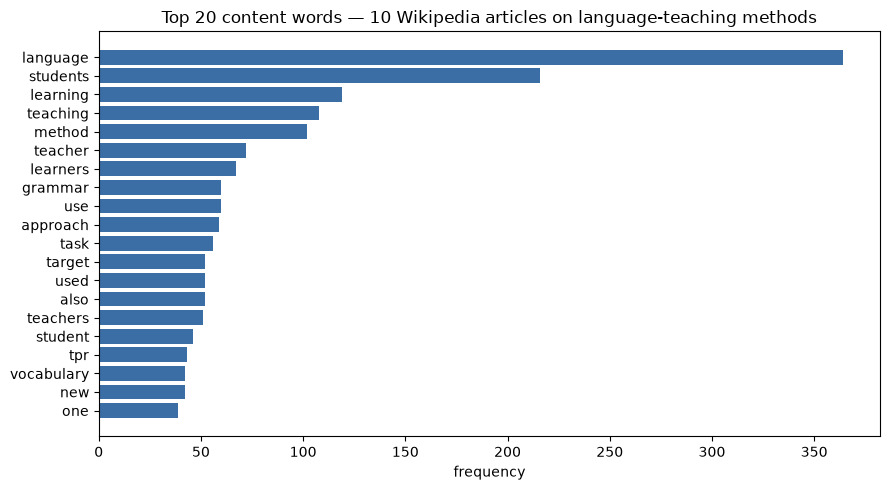

In [35]:
# Global frequency distribution across the corpus
global_counts = Counter(t for text in corpus.values() for t in content_tokens(tokenize(text)))
top = pd.DataFrame(global_counts.most_common(20), columns=["word", "freq"])

if not top.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(top["word"][::-1], top["freq"][::-1], color="#3b6ea5")
    ax.set_title(f"Top 20 content words — {len(corpus)} Wikipedia articles on language-teaching methods")
    ax.set_xlabel("frequency")
    plt.tight_layout()
    plt.show()
else:
    print("Corpus is empty (offline) — nothing to plot.")

In [36]:
# Document frequency + distinctive words per article (simple TF-IDF-like ratio, no sklearn)
import math

doc_tokens = {t: Counter(content_tokens(tokenize(txt))) for t, txt in corpus.items()}
df_counts = Counter(w for c in doc_tokens.values() for w in c)
N = len(doc_tokens)

distinctive = []
for title, counts in doc_tokens.items():
    total = sum(counts.values()) or 1
    scored = {w: (c / total) * math.log((1 + N) / (1 + df_counts[w])) for w, c in counts.items() if c >= 3}
    best = sorted(scored, key=scored.get, reverse=True)[:6]
    distinctive.append({"article": title, "distinctive_words": ", ".join(best)})

print("Words appearing in every article:", sorted(w for w, d in df_counts.items() if d == N)[:15])
pd.DataFrame(distinctive)

Words appearing in every article: ['approach', 'foreign', 'language', 'learning', 'students', 'target', 'teachers', 'teaching', 'used']


,article,distinctive_words
0,Grammar–translation method,"latin, literature, century, classical, translate, textbooks"
1,Direct method (education),"element, taught, inlingua, review, random, variations"
2,Audio-lingual method,"dialogue, audio-lingual, there's, dialogues, listening, drills"
3,Communicative language teaching,"clt, competence, partner, activity, instructor, communicative"
4,Task-based language learning,"task, tasks, cognitive, tblt, task-based, complexity"
5,Total physical response,"tpr, asher, commands, storytelling, children, physical"
6,Silent Way,"silent, chart, gattegno, sounds, help, color"
7,Suggestopedia,"suggestopedia, lozanov, session, asserts, music, claims"
8,Content and language integrated learning,"clil, cbi, immersion, european, content, term"
9,Natural approach,"terrell, krashen, natural, conscious, comprehensible, yes"


In [37]:
# Bridge to Datamuse: frequency profile of the corpus' top terms (general English frequency per million)
with build_session() as s:
    profile = []
    for w in top["word"].head(12):
        res = datamuse({"sp": w, "md": "f", "max": 1}, s)
        f = tag_value(res[0].get("tags", []), "f:") if res and res[0]["word"] == w else None
        profile.append({"word": w, "corpus_freq": global_counts[w], "english_freq_per_million": f})
        time.sleep(0.1)

profile_df = pd.DataFrame(profile)
if not profile_df.empty and profile_df["english_freq_per_million"].notna().any():
    profile_df["specialisation"] = profile_df["corpus_freq"] / profile_df["english_freq_per_million"].clip(lower=0.01)
    display(profile_df.sort_values("specialisation", ascending=False))
    print("High ratios flag domain terms that are frequent here but rare in general English (heuristic).")
else:
    display(profile_df)

,word,corpus_freq,english_freq_per_million,specialisation
6,learners,67,5.761302,11.629316
7,grammar,60,13.328882,4.501503
0,language,364,163.502230,2.226269
3,teaching,108,62.901940,1.716958
1,students,216,137.879575,1.566584
11,target,52,37.115716,1.401024
2,learning,119,98.584153,1.207091
5,teacher,72,60.627923,1.187572
10,task,56,73.259247,0.764409
4,method,102,139.448431,0.731453


High ratios flag domain terms that are frequent here but rare in general English (heuristic).


## 14. Boas práticas para consumir APIs

1. **Sempre `timeout`** (`requests` não tem timeout padrão). Use tupla `(connect, read)` quando fizer sentido.
2. **Trate erros por tipo** e use `raise_for_status()`; não engula exceções silenciosamente — registre em log.
3. **Identifique-se** com `User-Agent` descritivo e contato (exigido pela Wikipedia).
4. **Sessões** para reaproveitar conexões; feche-as (`with`).
5. **Rate limit + retry com backoff** apenas para erros transitórios; respeite `Retry-After`.
6. **Cache** com TTL adequado; nunca guarde respostas de erro.
7. **Peça só o necessário** (`fields=`, `max=`, `limit=`).
8. **Chaves e tokens em variáveis de ambiente** (ou `.env` fora do Git) — **nunca** no código ou no notebook.
9. **Logue** método, URL (sem segredos), status e latência para depurar e monitorar.
10. Leia os **termos de uso** e a licença dos dados (o texto da Wikipedia é CC BY-SA).

In [38]:
# Authentication patterns (illustrated with prepared requests — nothing is sent, no real secrets used)
api_key = os.environ.get("EXAMPLE_API_KEY", "demo-key-not-real")  # read from env, never hard-code

patterns = {
    "API key in header": requests.Request("GET", "https://api.example.com/v1/words", headers={"X-API-Key": api_key}),
    "Bearer token (OAuth2)": requests.Request("GET", "https://api.example.com/v1/words", headers={"Authorization": f"Bearer {api_key}"}),
    "HTTP Basic auth": requests.Request("GET", "https://api.example.com/v1/words", auth=("user", "pass")),
    "API key in query (avoid: leaks into logs)": requests.Request("GET", "https://api.example.com/v1/words", params={"api_key": api_key}),
}


def mask(value: str) -> str:
    """Mask a secret for safe display."""
    return value[:4] + "…" if len(value) > 4 else "***"


for name, r in patterns.items():
    p = r.prepare()
    auth_header = p.headers.get("Authorization") or p.headers.get("X-API-Key") or ""
    url = re.sub(r"(api_key=)[^&]+", lambda m: m.group(1) + "***", p.url)
    print(f"{name:42s} url={url} | auth={mask(auth_header) if auth_header else '-'}")

API key in header                          url=https://api.example.com/v1/words | auth=demo…
Bearer token (OAuth2)                      url=https://api.example.com/v1/words | auth=Bear…
HTTP Basic auth                            url=https://api.example.com/v1/words | auth=Basi…
API key in query (avoid: leaks into logs)  url=https://api.example.com/v1/words?api_key=*** | auth=-


In [39]:
class LoggedClient:
    """httpx.Client wrapper that logs every call (method, path, status, latency) and never logs secrets."""

    def __init__(self, base_url: str, **kwargs) -> None:
        self.records: list[dict] = []
        self.client = httpx.Client(
            base_url=base_url, headers=HEADERS, timeout=httpx.Timeout(TIMEOUT, connect=5.0),
            event_hooks={"request": [self._on_request], "response": [self._on_response]}, **kwargs,
        )

    def _on_request(self, request: httpx.Request) -> None:
        request.extensions["start"] = time.perf_counter()

    def _on_response(self, response: httpx.Response) -> None:
        req = response.request
        ms = (time.perf_counter() - req.extensions.get("start", time.perf_counter())) * 1000
        self.records.append({"method": req.method, "path": req.url.path, "status": response.status_code, "ms": round(ms, 1)})
        log.info("%s %s -> %s (%.0f ms)", req.method, req.url.path, response.status_code, ms)

    def get_json(self, path: str, **params) -> Any:
        try:
            r = self.client.get(path, params=params)
            r.raise_for_status()
            return r.json()
        except httpx.HTTPError as exc:
            log.warning("call failed: %s", exc.__class__.__name__)
            return None

    def __enter__(self):
        return self

    def __exit__(self, *exc) -> None:
        self.client.close()


with LoggedClient(DATAMUSE) as dm:
    dm.get_json("/words", ml="lesson plan", max=5)
    dm.get_json("/words", rel_ant="formal", max=5)
    dm.get_json("/sug", s="pronunc", max=5)  # autocomplete endpoint
    call_log = pd.DataFrame(dm.records)
call_log

2026-11-24 00:38:55,086 | INFO | httpx | HTTP Request: GET https://api.datamuse.com/words?ml=lesson+plan&max=5 "HTTP/1.1 200 OK"


2026-11-24 00:38:55,087 | INFO | api | GET /words -> 200 (28 ms)


2026-11-24 00:38:55,096 | INFO | httpx | HTTP Request: GET https://api.datamuse.com/words?rel_ant=formal&max=5 "HTTP/1.1 200 OK"


2026-11-24 00:38:55,096 | INFO | api | GET /words -> 200 (8 ms)


2026-11-24 00:38:55,105 | INFO | httpx | HTTP Request: GET https://api.datamuse.com/sug?s=pronunc&max=5 "HTTP/1.1 200 OK"


2026-11-24 00:38:55,106 | INFO | api | GET /sug -> 200 (8 ms)


,method,path,status,ms
0,GET,/words,200,27.5
1,GET,/words,200,8.4
2,GET,/sug,200,8.5


### Resumo e próximos passos

| Tema | O que pratiquei |
| --- | --- |
| HTTP/REST | métodos, status, headers, requisições preparadas |
| `requests` | `Response`, `.json()`, `raise_for_status()`, hierarquia de exceções |
| `httpx` | cliente síncrono, `AsyncClient` + `asyncio.gather`, `MockTransport`, *event hooks* |
| Sessões | *keep-alive*, `HTTPAdapter` + `Retry` do urllib3 |
| Rate limit / retry | intervalo mínimo, *token bucket*, backoff manual e `tenacity` |
| Paginação | offset/limit (Open Library) e cursor `continue` (MediaWiki) |
| Cache | `lru_cache`, TTL em dicionário/JSON, `requests_cache` |
| Dados | `json_normalize`, DataFrames, mini-corpus de 10 artigos com frequências e TTR |

**Reflexão (linguística + DS):** APIs como a Datamuse e a Wikipedia viram fontes de dados linguísticos prontas para ensino — glossários, colocações, pares mínimos, perfis de vocabulário. Mas são fontes com **vieses e limites**: a Wikipedia reflete um registro enciclopédico, e as frequências da Datamuse vêm de um corpus geral, não de alunos brasileiros. As faixas "comum/raro" usadas aqui são limiares arbitrários, não níveis CEFR.

**Próximos passos:** web scraping responsável (`BeautifulSoup`, `robots.txt`) e, na Fase 2, EDA de corpora coletados por API.

In [40]:
# Housekeeping: remove the temporary cache directory created by this notebook
import shutil

shutil.rmtree(tmp_dir, ignore_errors=True)
print("Temporary files removed:", not tmp_dir.exists())
print(f"Notebook finished. Online during execution: {ONLINE}")

Temporary files removed: True
Notebook finished. Online during execution: True
